<a href="https://colab.research.google.com/github/FridaOyucho/Malaria-Maps/blob/main/SubCounty_Malaria_Map.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

In [4]:
YEAR = 2026
RATE = "Confirmed Malaria cases Per 1000 Population"

# 1. Load the data
gdf = gpd.read_file("geoBoundaries-KEN-ADM2.shp")      # your boundary file (.shp or .geojson)
df = pd.read_excel("SubCounty Data Select Counties.xls")                  # your full dataset


In [5]:
gdf.head()

,shapeName,shapeISO,shapeID,shapeGroup,shapeType,geometry
0,Ainabkoi,None,3690345B95414198105650,KEN,ADM2,"POLYGON ((35.4633 0.5072, 35.46319 0.50205, 35..."
1,Ainamoi,None,3690345B54801368411234,KEN,ADM2,"POLYGON ((35.32495 -0.25056, 35.32775 -0.25211..."
2,Aldai,None,3690345B36924206491537,KEN,ADM2,"POLYGON ((35.13034 0.1363, 35.12981 0.13534, 3..."
3,Alego Usonga,None,3690345B57306569752992,KEN,ADM2,"POLYGON ((34.21848 0.16479, 34.21617 0.1618, 3..."
4,Awendo,None,3690345B13715496647196,KEN,ADM2,"POLYGON ((34.62157 -0.9854, 34.61197 -0.996, 3..."


In [6]:
df.head()

,Year,County,SubCounty,Confirmed Malaria (only Positive cases),Confirmed Malaria cases Per 1000 Population,Incidence of Outpatient Malaria (per 1000 population),Malaria Test Positivity Rate - Overall (TPR),Proportion of suspected malaria cases tested,Total Suspected malaria cases (<5Years MoH 705A+>5Years MoH 705B),Total Outpatient attendance Workload,Total number of malaria tests (RDT + BS) MOH706
0,2026,Busia,Bunyala,6988,139.65,67.88,37.5,99.18,16873,69770.0,7736
1,2026,Busia,Butula,22101,211.96,130.22,47.0,97.81,46479,147574.0,20483
2,2026,Busia,Matayos,17374,223.53,101.38,19.5,99.99,75795,280846.0,56436
3,2026,Busia,Nambale,13692,164.22,102.18,25.7,98.84,49205,114169.0,30363
4,2026,Busia,Samia,10598,200.14,81.49,32.6,99.97,32738,108606.0,18091


In [18]:
df = df.rename(columns={"ShapeName": "shapeName"})

In [19]:
df.head()

,Year,County,shapeName,Confirmed Malaria (only Positive cases),Confirmed Malaria cases Per 1000 Population,Incidence of Outpatient Malaria (per 1000 population),Malaria Test Positivity Rate - Overall (TPR),Proportion of suspected malaria cases tested,Total Suspected malaria cases (<5Years MoH 705A+>5Years MoH 705B),Total Outpatient attendance Workload,Total number of malaria tests (RDT + BS) MOH706
0,2026,Busia,Bunyala,6988,139.65,67.88,37.5,99.18,16873,69770.0,7736
1,2026,Busia,Butula,22101,211.96,130.22,47.0,97.81,46479,147574.0,20483
2,2026,Busia,Matayos,17374,223.53,101.38,19.5,99.99,75795,280846.0,56436
3,2026,Busia,Nambale,13692,164.22,102.18,25.7,98.84,49205,114169.0,30363
4,2026,Busia,Samia,10598,200.14,81.49,32.6,99.97,32738,108606.0,18091


In [16]:
#Change subcounty to ShapeName
df = df.rename(columns={'Shapename': 'shapeName'})

In [9]:
# 2. Keep one year only (otherwise the join duplicates counties)
df["Year"] = pd.to_numeric(df["Year"], errors="coerce")
df = df[df["Year"] == 2026]

In [14]:
gdf.head()

,shapeName,shapeISO,shapeID,shapeGroup,shapeType,geometry
0,Ainabkoi,None,3690345B95414198105650,KEN,ADM2,"POLYGON ((35.4633 0.5072, 35.46319 0.50205, 35..."
1,Ainamoi,None,3690345B54801368411234,KEN,ADM2,"POLYGON ((35.32495 -0.25056, 35.32775 -0.25211..."
2,Aldai,None,3690345B36924206491537,KEN,ADM2,"POLYGON ((35.13034 0.1363, 35.12981 0.13534, 3..."
3,Alego Usonga,None,3690345B57306569752992,KEN,ADM2,"POLYGON ((34.21848 0.16479, 34.21617 0.1618, 3..."
4,Awendo,None,3690345B13715496647196,KEN,ADM2,"POLYGON ((34.62157 -0.9854, 34.61197 -0.996, 3..."


In [20]:
df.head()

,Year,County,shapeName,Confirmed Malaria (only Positive cases),Confirmed Malaria cases Per 1000 Population,Incidence of Outpatient Malaria (per 1000 population),Malaria Test Positivity Rate - Overall (TPR),Proportion of suspected malaria cases tested,Total Suspected malaria cases (<5Years MoH 705A+>5Years MoH 705B),Total Outpatient attendance Workload,Total number of malaria tests (RDT + BS) MOH706
0,2026,Busia,Bunyala,6988,139.65,67.88,37.5,99.18,16873,69770.0,7736
1,2026,Busia,Butula,22101,211.96,130.22,47.0,97.81,46479,147574.0,20483
2,2026,Busia,Matayos,17374,223.53,101.38,19.5,99.99,75795,280846.0,56436
3,2026,Busia,Nambale,13692,164.22,102.18,25.7,98.84,49205,114169.0,30363
4,2026,Busia,Samia,10598,200.14,81.49,32.6,99.97,32738,108606.0,18091


In [21]:
# 3. Check that county names match (should print an empty set)
print("Unmatched names:", set(df["shapeName"]) - set(gdf["shapeName"]))

Unmatched names: {'Teso Cetral', 'Kieni West', 'Kadibo', 'Olkalou', 'Oljoroorok', 'Kieni East', 'Nyeri South', 'Kirinyaga South', 'Rachuonyo East ', 'Lokiriama', 'Kibish', 'Suguta', 'Mukurweini', 'Mathira East', 'Rachuonyo South', 'Kirinyaga East', 'Kirinyaga North/Mwea', 'Bunyala', 'Samia', 'Kakuma Refugee', 'Mathira West', 'Aroo', 'Lokichoggio', 'Kirinyaga West', 'Rachuonyo North', 'Nyeri Central', 'Suba West'}


In [22]:
import re

def clean_name(x):
    x = str(x).strip().lower()
    x = re.sub(r"[^a-z0-9]", "", x)   # removes spaces, -, ', etc.
    return x

df["shapeName_clean"] = df["shapeName"].apply(clean_name)
gdf["shapeName_clean"] = gdf["shapeName"].apply(clean_name)

unmatched = set(df["shapeName_clean"]) - set(gdf["shapeName_clean"])

print("Remaining unmatched:", unmatched)
print("Number unmatched:", len(unmatched))

Remaining unmatched: {'oljoroorok', 'kakumarefugee', 'rachuonyonorth', 'nyerisouth', 'nyericentral', 'lokichoggio', 'kienieast', 'kieniwest', 'kirinyagaeast', 'tesocetral', 'bunyala', 'mukurweini', 'lokiriama', 'aroo', 'kibish', 'kirinyagawest', 'samia', 'kadibo', 'mathiraeast', 'subawest', 'suguta', 'rachuonyoeast', 'rachuonyosouth', 'kirinyagasouth', 'mathirawest', 'kirinyaganorthmwea'}
Number unmatched: 26


In [23]:
from difflib import get_close_matches

unmatched_original = df.loc[
    ~df["shapeName_clean"].isin(gdf["shapeName_clean"]),
    "shapeName"
].unique()

shape_names = gdf["shapeName"].dropna().unique()

for name in unmatched_original:
    matches = get_close_matches(
        name,
        shape_names,
        n=3,
        cutoff=0.5
    )
    print(f"{name:30} -> {matches}")

Bunyala                        -> ['Funyula', 'Budalangi', 'Butula']
Samia                          -> ['Sabatia', 'Saboti', 'Hamisi']
Teso Cetral                    -> ['Bomet Central', 'Kisumu Central', 'Igembe Central']
Rachuonyo East                 -> ['Karachuonyo', 'Suna East', 'Lamu East']
Rachuonyo North                -> ['Gatundu North', 'Baringo North', 'Narok North']
Rachuonyo South                -> ['Gatundu South', 'Baringo South', 'Pokot South']
Suba West                      -> ['Suna West', 'Kuria West', 'Mumias West']
Kadibo                         -> ['Kanduyi', 'Kangundo', 'Kibra']
Kirinyaga East                 -> ['Kuria East', 'Kirinyaga Central', 'Kitui East']
Kirinyaga North/Mwea           -> ['Kirinyaga Central', 'Baringo North', 'Keiyo North']
Kirinyaga South                -> ['Baringo South', 'Kitui South', 'Keiyo South']
Kirinyaga West                 -> ['Kirinyaga Central', 'Kuria West', 'Kitui West']
Oljoroorok                     -> ['Ol Jorok', 'Njo

In [25]:
# Exact merge - no name corrections
merged = gdf.merge(
    df,
    on="shapeName",
    how="left"
)

print(merged.shape)
merged.head()

(290, 18)


,shapeName,shapeISO,shapeID,shapeGroup,shapeType,geometry,shapeName_clean_x,Year,County,Confirmed Malaria (only Positive cases),Confirmed Malaria cases Per 1000 Population,Incidence of Outpatient Malaria (per 1000 population),Malaria Test Positivity Rate - Overall (TPR),Proportion of suspected malaria cases tested,Total Suspected malaria cases (<5Years MoH 705A+>5Years MoH 705B),Total Outpatient attendance Workload,Total number of malaria tests (RDT + BS) MOH706,shapeName_clean_y
0,Ainabkoi,None,3690345B95414198105650,KEN,ADM2,"POLYGON ((35.4633 0.5072, 35.46319 0.50205, 35...",ainabkoi,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Ainamoi,None,3690345B54801368411234,KEN,ADM2,"POLYGON ((35.32495 -0.25056, 35.32775 -0.25211...",ainamoi,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Aldai,None,3690345B36924206491537,KEN,ADM2,"POLYGON ((35.13034 0.1363, 35.12981 0.13534, 3...",aldai,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Alego Usonga,None,3690345B57306569752992,KEN,ADM2,"POLYGON ((34.21848 0.16479, 34.21617 0.1618, 3...",alegousonga,2026.0,Siaya,47998.0,277.11,178.38,33.0,99.43,132845.0,365450.0,67457.0,alegousonga
4,Awendo,None,3690345B13715496647196,KEN,ADM2,"POLYGON ((34.62157 -0.9854, 34.61197 -0.996, 3...",awendo,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [26]:
indicator = "Confirmed Malaria cases Per 1000 Population"

print("Matched:", merged[indicator].notna().sum())
print("Unmatched:", merged[indicator].isna().sum())

Matched: 44
Unmatched: 246


In [27]:
bins = [0, 1, 5, 20, 40, 100, 200, 400, float("inf")]

labels = [
    "<1",
    "1–<5",
    "5–<20",
    "20–<40",
    "40–<100",
    "100–<200",
    "200–<400",
    "≥400"
]

merged["Malaria_Category"] = pd.cut(
    merged[indicator],
    bins=bins,
    labels=labels,
    right=False
)

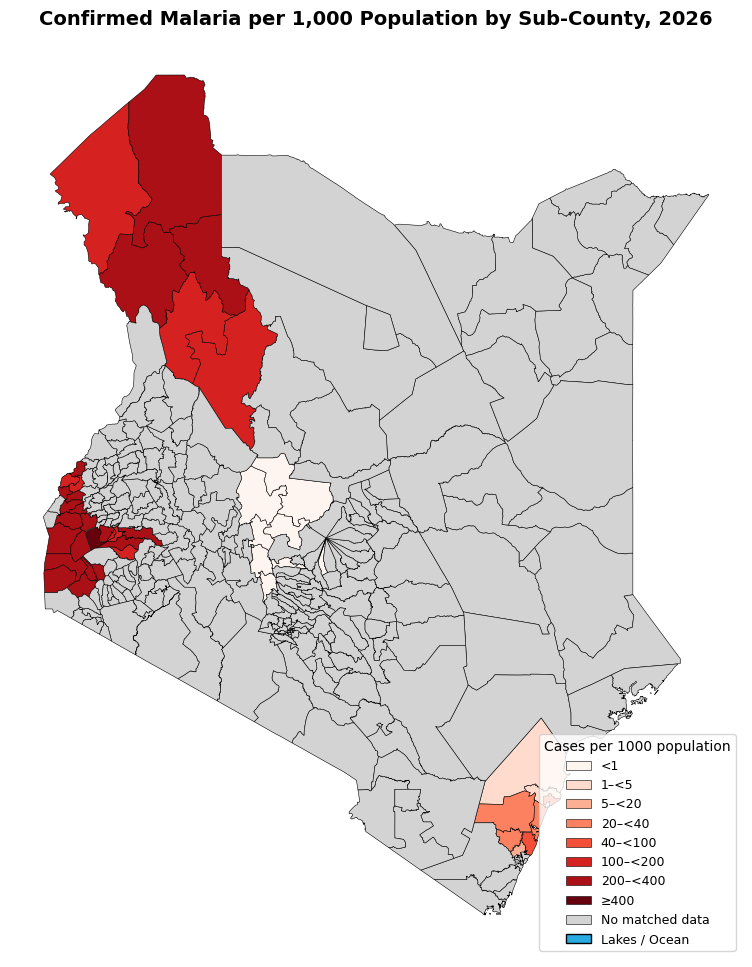

In [29]:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

fig, ax = plt.subplots(figsize=(10, 12))

# Water background
ax.set_facecolor("#29ABE2")

# Plot malaria categories
merged.plot(
    column="Malaria_Category",
    categorical=True,
    cmap="Reds",
    linewidth=0.4,
    edgecolor="black",
    legend=True,
    missing_kwds={
        "color": "lightgrey",
        "edgecolor": "black",
        "label": "No matched data"
    },
    ax=ax
)

ax.set_title(
    "Confirmed Malaria per 1,000 Population by Sub-County, 2026",
    fontsize=14,
    fontweight="bold"
)

ax.axis("off")

# Get the automatically generated legend
legend = ax.get_legend()

if legend is not None:

    handles = legend.legend_handles
    labels = [text.get_text() for text in legend.get_texts()]

    # Add Lakes / Ocean
    handles.append(
        Patch(
            facecolor="#29ABE2",
            edgecolor="black",
            label="Lakes / Ocean"
        )
    )
    labels.append("Lakes / Ocean")

    # Recreate legend at bottom-right
    ax.legend(
        handles=handles,
        labels=labels,
        title="Cases per 1000 population",
        loc="lower right",
        frameon=True,
        fontsize=9,
        title_fontsize=10
    )

plt.show()

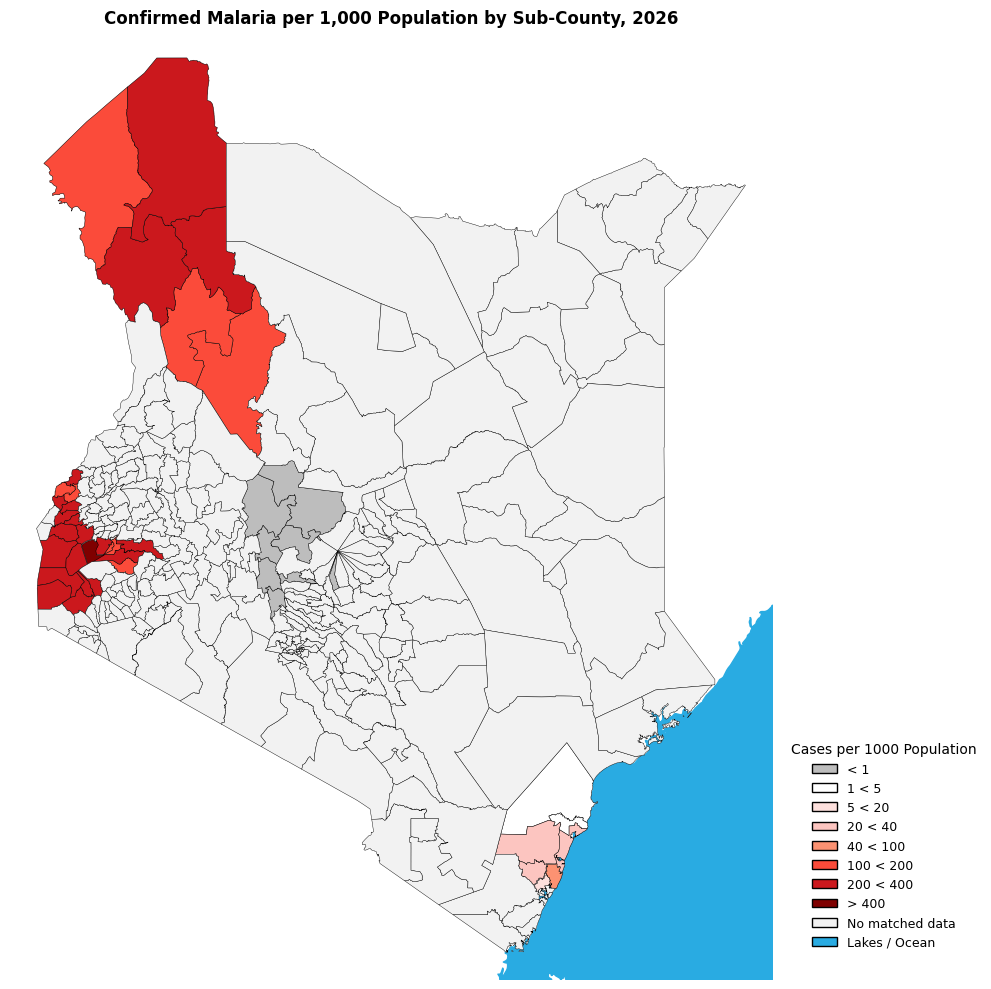

In [39]:
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from shapely.geometry import box

water = "#29ABE2"

colors = {
    "< 1": "#BDBDBD",
    "1 < 5": "#FFFFFF",
    "5 < 20": "#FDE0DD",
    "20 < 40": "#FCC5C0",
    "40 < 100": "#FC9272",
    "100 < 200": "#FB4B3A",
    "200 < 400": "#CB181D",
    "> 400": "#7F0000"
}

# Kenya extent
xmin, ymin, xmax, ymax = merged.total_bounds
bbox = gpd.GeoDataFrame(
    geometry=[box(xmin - 0.3, ymin - 0.3, xmax + 0.3, ymax + 0.3)],
    crs=merged.crs
)

# Load water layers
lakes = gpd.read_file(
    "ne_10m_lakes.shx"
).to_crs(merged.crs)

ocean = gpd.read_file(
    "ne_10m_ocean.shp"
).to_crs(merged.crs)

lakes = gpd.clip(lakes, bbox)
ocean = gpd.clip(ocean, bbox)

fig, ax = plt.subplots(figsize=(11, 10))
ax.set_facecolor("white")

# Ocean
ocean.plot(ax=ax, color=water, edgecolor=water, zorder=0)

# Malaria strata
for cat, colour in colors.items():
    merged[merged["Malaria_Category"] == cat].plot(
        ax=ax,
        color=colour,
        edgecolor="black",
        linewidth=0.35,
        zorder=2
    )

# Unmatched areas – lighter like the reference
merged[merged["Malaria_Category"].isna()].plot(
    ax=ax,
    color="#F2F2F2",
    edgecolor="black",
    linewidth=0.3,
    zorder=2
)

# Legend
handles = [
    Patch(facecolor=c, edgecolor="black", label=l)
    for l, c in colors.items()
]

handles += [
    Patch(facecolor="#F2F2F2", edgecolor="black", label="No matched data"),
    Patch(facecolor=water, edgecolor="black", label="Lakes / Ocean")
]

ax.legend(
    handles=handles,
    title="Cases per 1000 Population",
    loc="lower left",
    bbox_to_anchor=(1.01, 0.02),
    frameon=False,
    fontsize=9,
    title_fontsize=10
)

# Force map back to Kenya
ax.set_xlim(xmin - 0.3, xmax + 0.3)
ax.set_ylim(ymin - 0.3, ymax + 0.3)

ax.set_title(
    "Confirmed Malaria per 1,000 Population by Sub-County, 2026",
    fontweight="bold"
)

ax.axis("off")
plt.tight_layout()
plt.show()